# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2026-03-19"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p19"
subproj <- "AVGUSTINOVA_22_23"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "MALAT1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

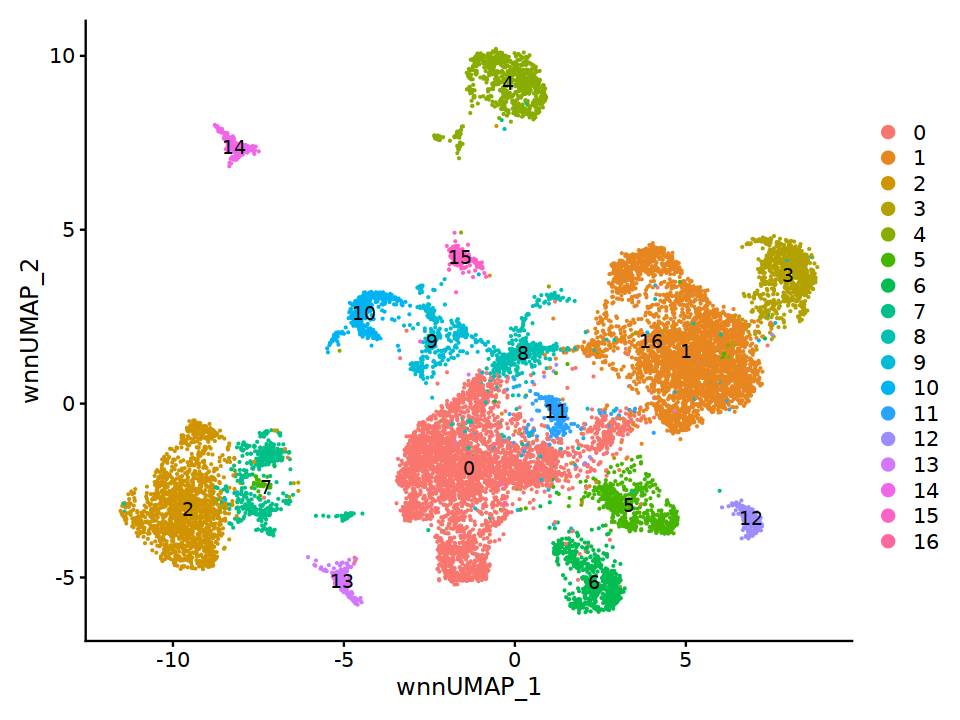

In [10]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

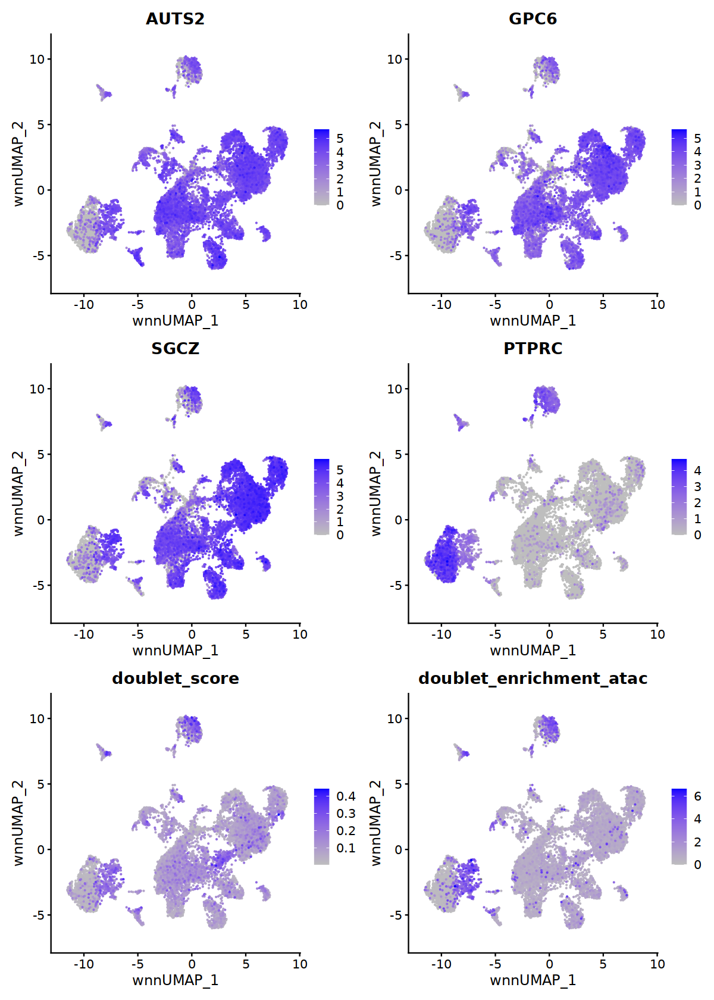

In [11]:
options(repr.plot.width = 10, repr.plot.height = 14)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("AUTS2","GPC6", "SGCZ", "PTPRC", "doublet_score", "doublet_enrichment_atac"),ncol=2,
            cols = c("gray", "blue"),  order=T)

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

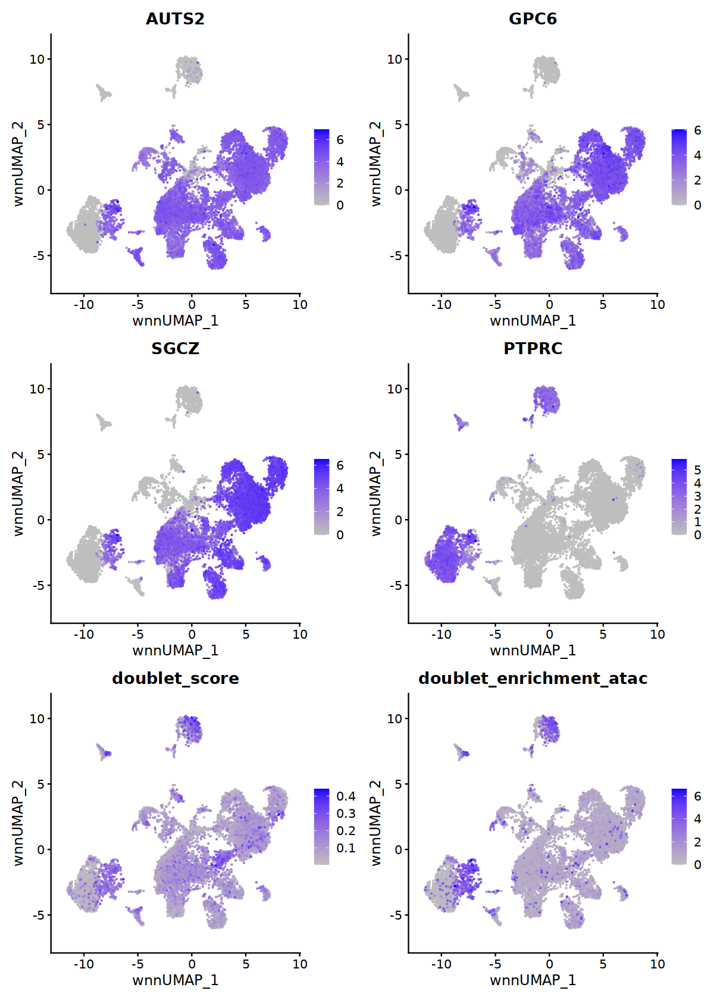

In [15]:
options(repr.plot.width = 10, repr.plot.height = 14)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("AUTS2","GPC6", "SGCZ", "PTPRC", "doublet_score", "doublet_enrichment_atac"),ncol=2,
            cols = c("gray", "blue"), order=T)

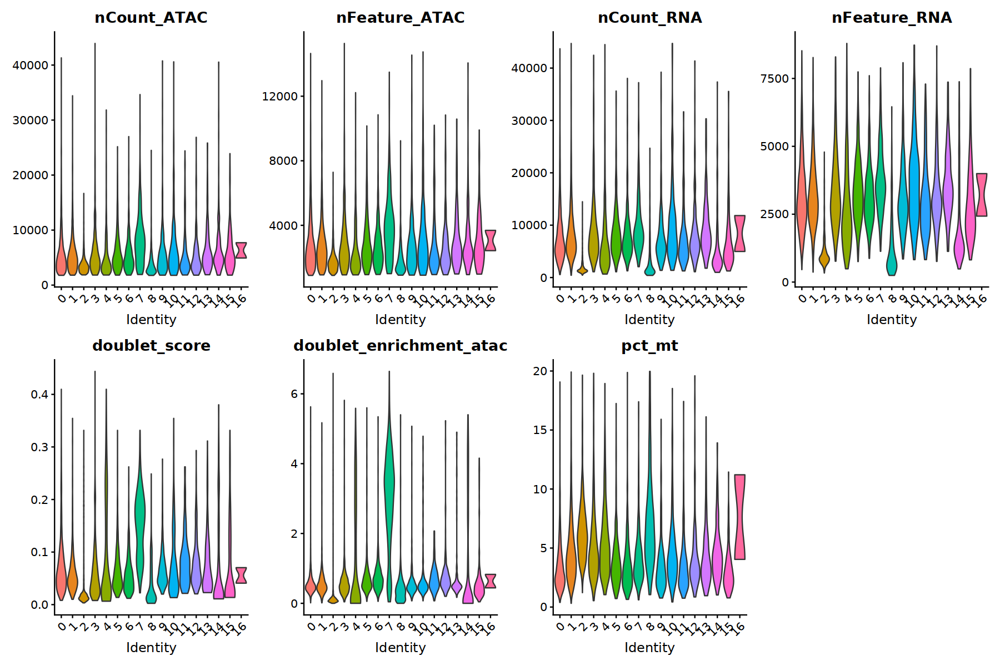

In [16]:
options(repr.plot.width = 15, repr.plot.height = 10)
VlnPlot(seurat_obj,features=c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score",
             "doublet_enrichment_atac", "pct_mt"), pt.size=0, ncol=4)

Not everything looks like RNA ambient, remove actual doublets.

In [17]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  cluster=c(4, 14),
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.05,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 944
Number of edges: 35612

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9713
Number of communities: 3
Elapsed time: 0 seconds


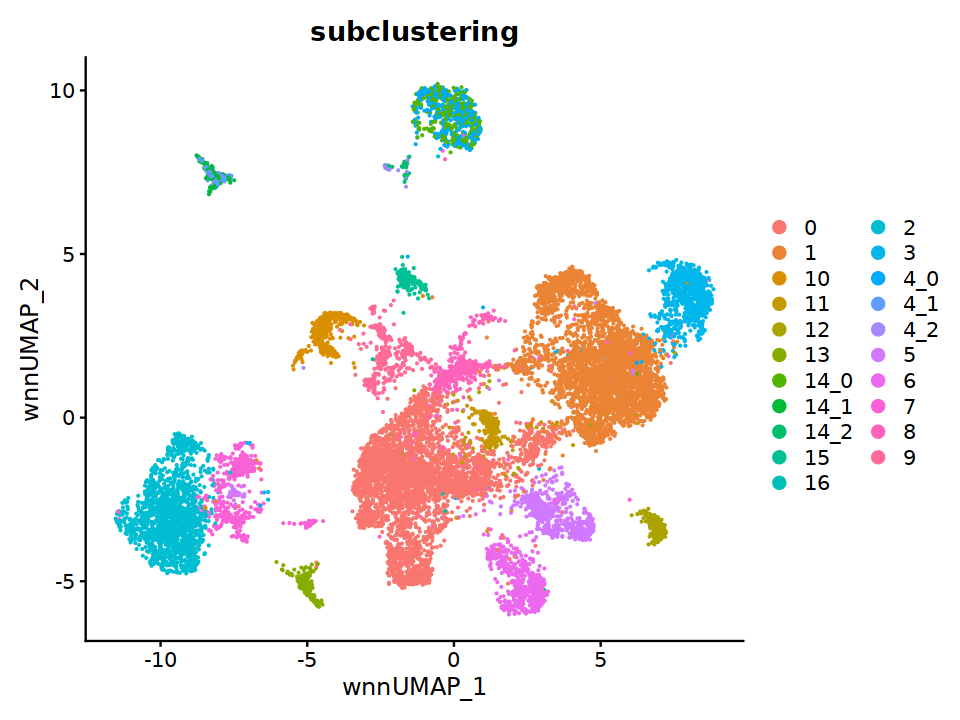

In [18]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering")

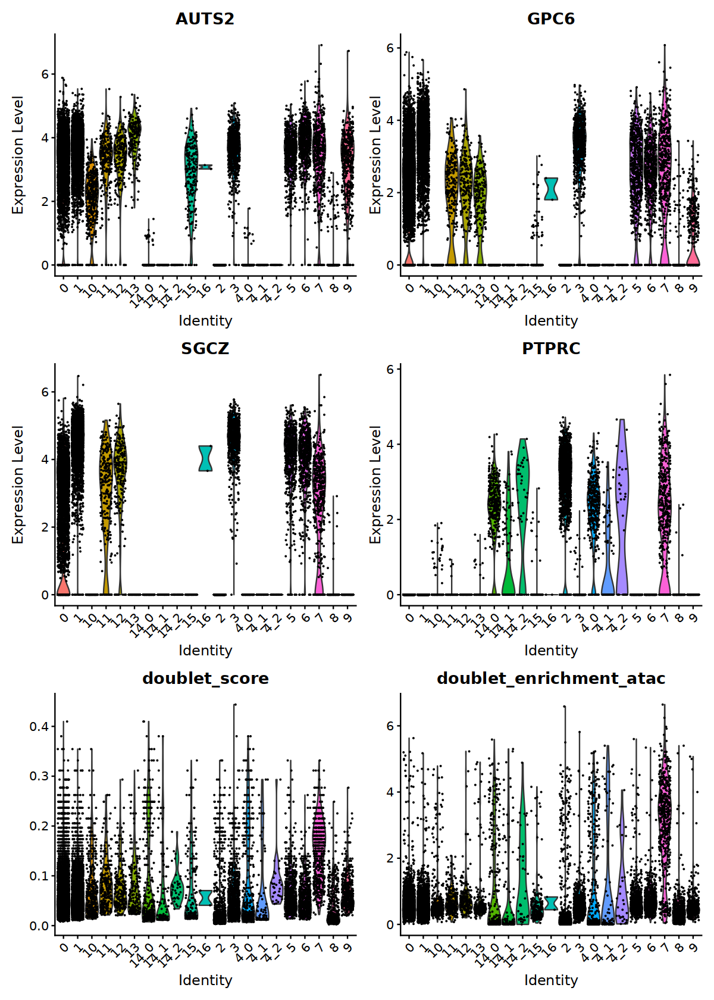

In [19]:
options(repr.plot.width = 10, repr.plot.height = 14)
VlnPlot(seurat_obj, features=c("AUTS2","GPC6", "SGCZ", "PTPRC", "doublet_score", "doublet_enrichment_atac"),
        ncol=2, group.by="subclustering")

Low quality cells 

In [20]:
markers <- FindMarkers(seurat_obj, ident.1 = "8", logfc.threshold=0.2, only.pos = T)
markers %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=20)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FTL,6.415955e-148,2.731084,0.952,0.956,2.079219e-143
C1QB,1.792560e-42,2.711086,0.330,0.128,5.809149e-38
C1QA,7.237080e-51,2.369709,0.323,0.108,2.345321e-46
RPL39,3.604779e-160,1.968248,0.927,0.938,1.168201e-155
RPL32,5.867497e-198,1.880199,0.964,0.981,1.901480e-193
RPS27,1.694175e-140,1.871715,0.900,0.914,5.490313e-136
RPL31,1.857064e-144,1.868427,0.907,0.931,6.018189e-140
PLCG2,5.044542e-24,1.865633,0.645,0.780,1.634785e-19
AC105402.3,1.026693e-57,1.842601,0.759,0.813,3.327205e-53


Difficult to isolate by subclustering

In [21]:
df_tmp <- FetchData(seurat_obj, vars = "doublet_enrichment_atac")

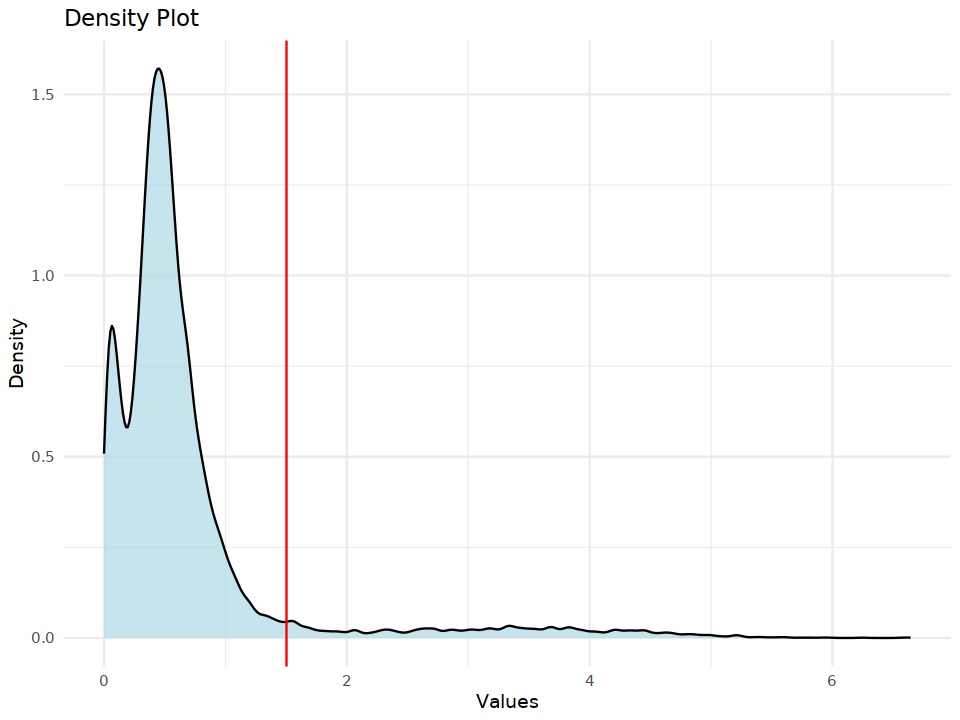

In [22]:
options(repr.plot.width = 8, repr.plot.height = 6)
ggplot(df_tmp, aes(x = doublet_enrichment_atac)) +
  geom_density(fill = "lightblue", color = "black", alpha = 0.7) +
  labs(
    title = "Density Plot",
    x = "Values",
    y = "Density"
  ) +
  geom_vline(xintercept =1.5, color="red") +
  theme_minimal()


In [23]:
# apply filters
seurat_obj <- subset(seurat_obj, subset = doublet_enrichment_atac < 1.5)
seurat_obj <- subset(seurat_obj, ident = 8, invert=T)

## Re-normalize

In [24]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [25]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [26]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [27]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

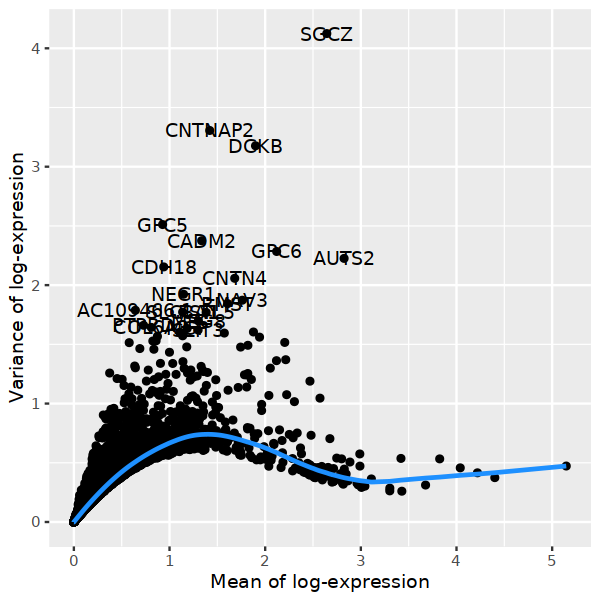

In [28]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [29]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 4712
[1] 4712


In [30]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AUTS2, NFIB, SSBP2, HMGA2, MIR100HG, NFIA, PARD3, TTC28, GPC6, LINC00882 
	   AP001977.1, ZEB1, MIR99AHG, SGCZ, NAV3, GULP1, ALCAM, EYA1, CNTN4, CASC15 
	   RMST, DGKB, EPHA4, BBX, GRIP1, ANGPT1, FSTL5, L3MBTL4, PDGFC, RERE 
Negative:  SRGN, HLA-B, PTPRC, CD74, CHST11, HLA-A, ARHGAP15, ATXN1, HLA-DRB1, B2M 
	   SAMSN1, HLA-C, RGS1, DPYD, PDE4B, HLA-DRA, FYB1, SMAP2, DOCK8, ELL2 
	   LRMDA, C1QB, CELF2, C1QA, GLUL, PLXDC2, ELMO1, ACSL1, CD163, CTSS 
PC_ 2 
Positive:  LINC01934, TOX, ETS1, CCL5, SKAP1, PRKCH, LYST, THEMIS, GZMK, IKZF2 
	   DTHD1, NKG7, FYN, ITGA4, CD2, NCALD, GZMA, IKZF3, PDE3B, KLF12 
	   CD247, CST7, PAM, IL32, BICDL1, TSPAN5, CNOT6L, SLFN12L, CCL4, ATXN1 
Negative:  LRMDA, DOCK4, PLXDC2, KCNMA1, RNF144B, AL162414.1, ACSL1, CD163, RAB31, CD86 
	   KYNU, FMNL2, SLC1A3, NPL, ABCA1, GLUL, MS4A4A, MERTK, PLA2G7, MS4A7 
	   CPVL, SLCO2B1, TNS3, RAB20, TNFSF13B, CR1, GAB2, KMO, C1QC, TLR2 
PC_ 3 
Positive:  CNTNAP2, FRMD4A

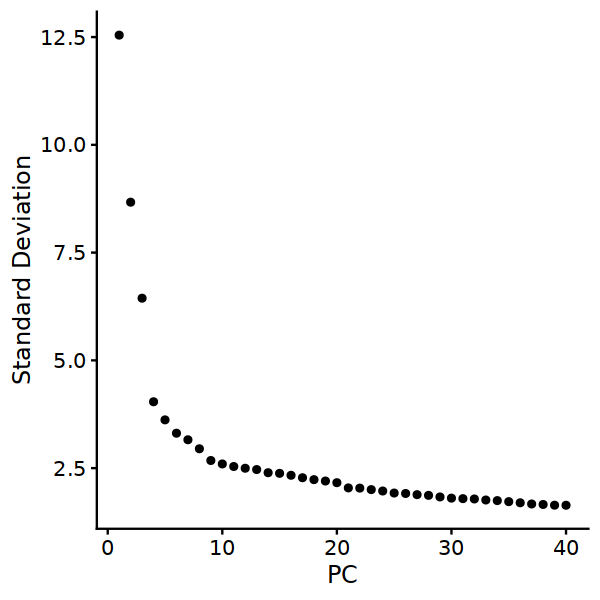

In [31]:
ElbowPlot(seurat_obj, n=40)

In [32]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
  assay.use = assay_ch
)

Suggested parameter: assay instead of assay.use


17:23:22 UMAP embedding parameters a = 0.9922 b = 1.112

17:23:22 Read 12863 rows and found 20 numeric columns

17:23:22 Using Annoy for neighbor search, n_neighbors = 30

17:23:22 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:23:23 Writing NN index file to temp file /scratch_tmp/61032904/RtmpeOvnrp/file25f07296c1d1a

17:23:23 Searching Annoy index using 1 thread, search_k = 3000

17:23:27 Annoy recall = 100%

17:23:28 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:23:30 Initializing from normalized Laplacian + noise (using irlba)

17:23:31 Commencing optimization for 200 epochs, with 528790 positive edges

17:23:46 Optimization finished



In [33]:
seurat_obj

An object of class Seurat 
119668 features across 12863 samples within 3 assays 
Active assay: RNA_decontx (32116 features, 4712 variable features)
 2 other assays present: ATAC, RNA
 5 dimensional reductions calculated: pca, umap, lsi.atac, umap.atac, wnn.umap

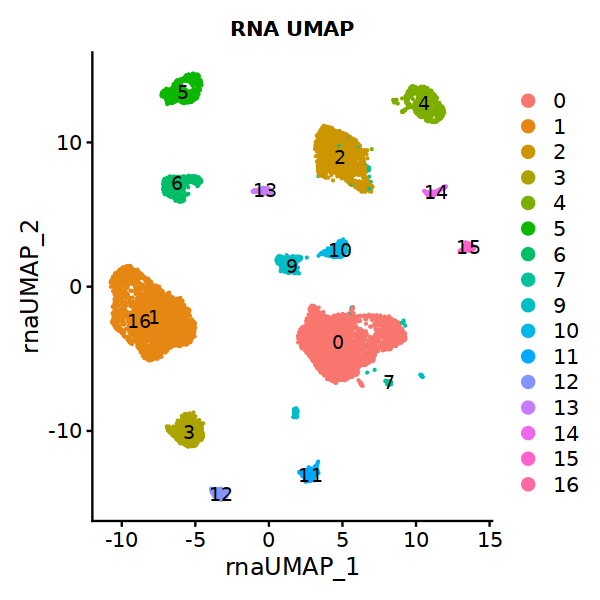

In [34]:
DimPlot(seurat_obj, reduction = "umap", label=T) + ggtitle(glue::glue('RNA UMAP')) + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

### ATAC

In [35]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [36]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



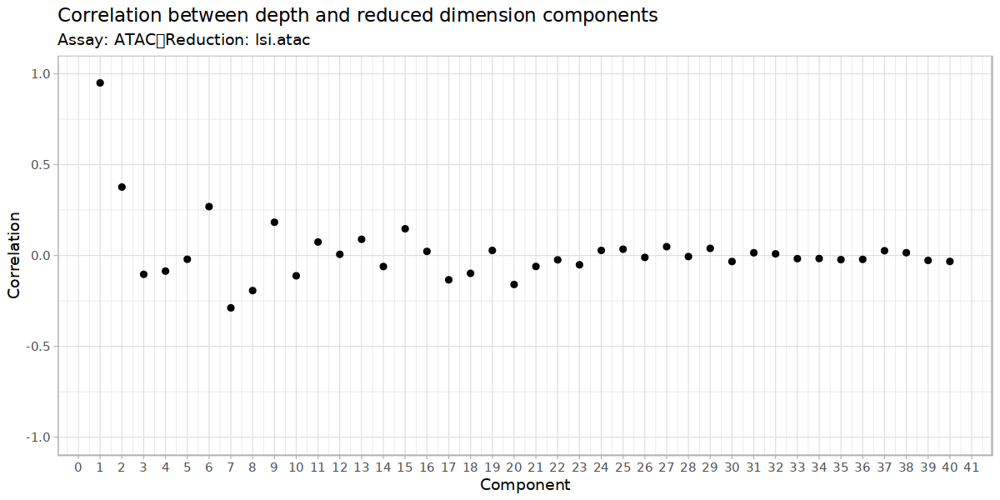

In [37]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

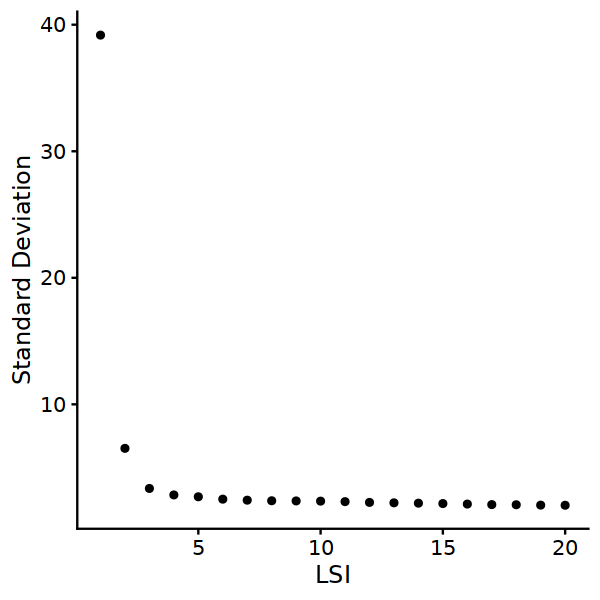

In [38]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [39]:
DefaultAssay(seurat_obj) <- assay_ch

In [40]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [41]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5,
   min.dist = 1  
)

17:24:41 UMAP embedding parameters a = 0.115 b = 1.929

17:24:42 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

17:24:43 Initializing from normalized Laplacian + noise (using irlba)

17:24:44 Commencing optimization for 200 epochs, with 382476 positive edges

17:25:00 Optimization finished



In [42]:
seurat_obj <- FindClusters(seurat_obj, resolution = reso,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 12863
Number of edges: 445986

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9862
Number of communities: 20
Elapsed time: 1 seconds


5 singletons identified. 15 final clusters.



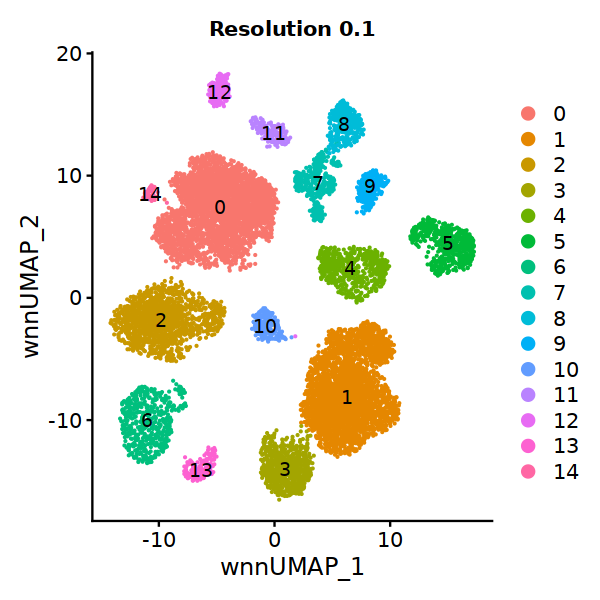

In [43]:
options(repr.plot.width = 5, repr.plot.height = 5)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T)+ ggtitle(glue::glue('Resolution {reso}')) + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))  

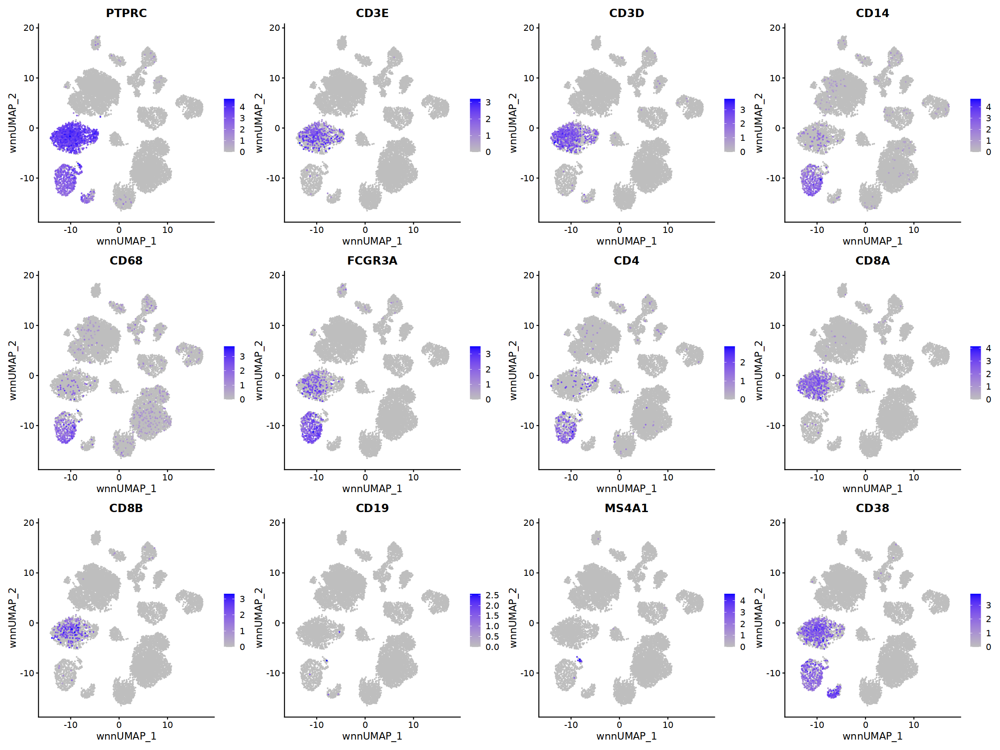

In [44]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

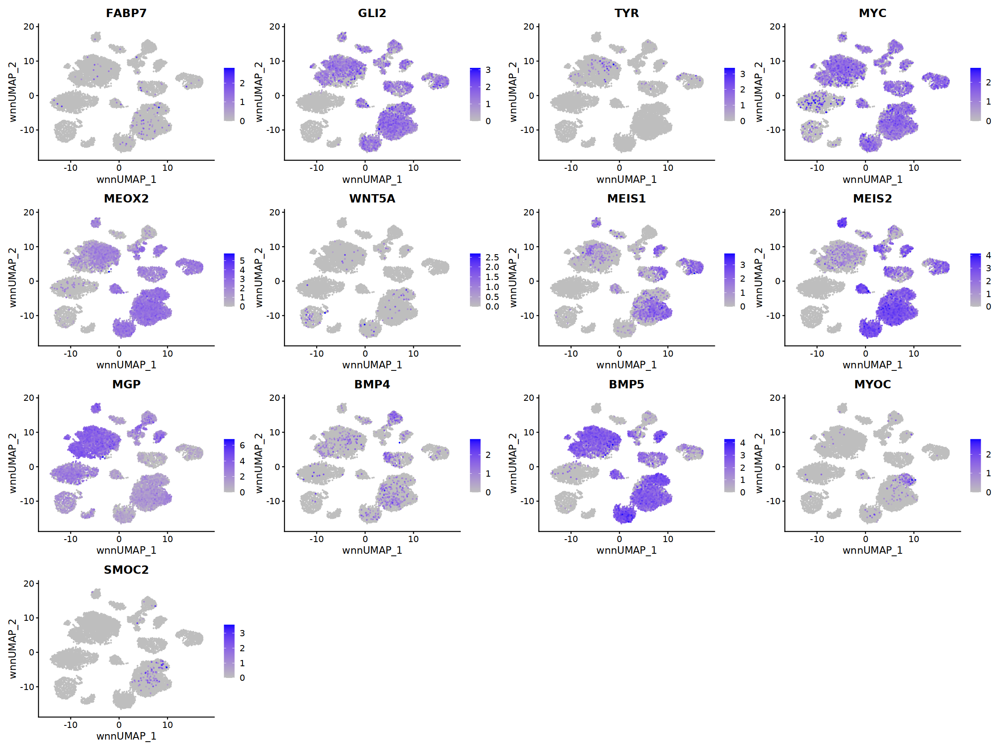

In [45]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), order=T, min.cutoff = 0)

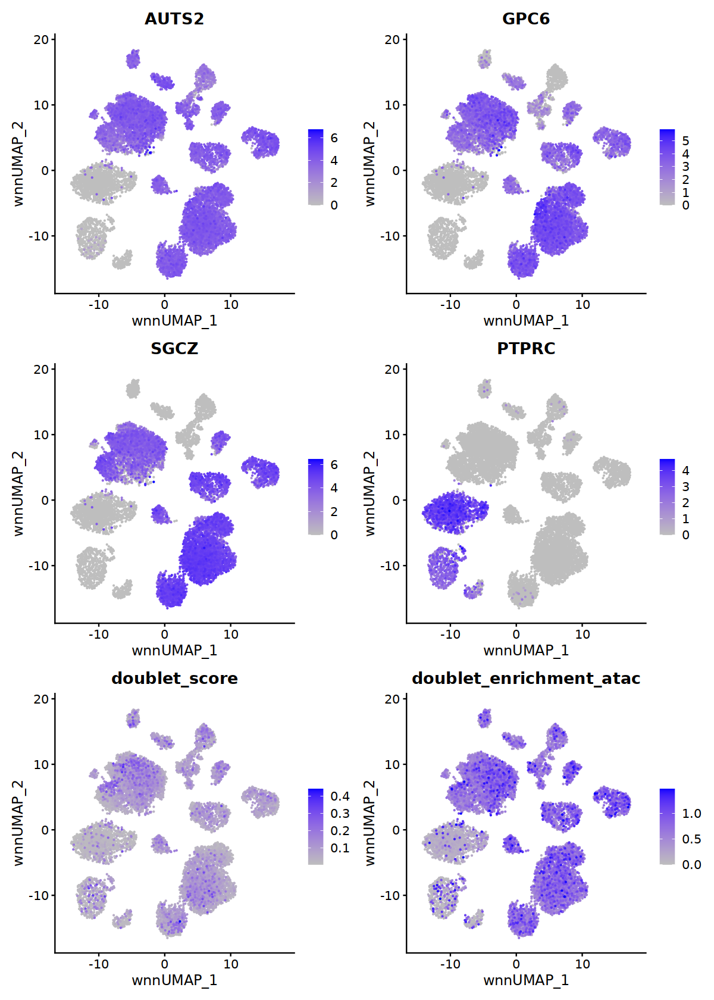

In [46]:
options(repr.plot.width = 10, repr.plot.height = 14)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("AUTS2","GPC6", "SGCZ", "PTPRC", "doublet_score", "doublet_enrichment_atac"),ncol=2,
            cols = c("gray", "blue"),  order=T)

In [47]:
colnames(seurat_obj@meta.data)

[1] "orig.ident"                 "nCount_ATAC"               
 [3] "nFeature_ATAC"              "nCount_RNA"                
 [5] "nFeature_RNA"               "is_cell"                   
 [7] "atac_fragments"             "atac_peak_region_fragments"
 [9] "fragments"                  "mononucleosomal"           
[11] "nucleosome_free"            "reads_count"               
[13] "FRiP"                       "caller"                    
[15] "nucleosome_signal"          "nucleosome_percentile"     
[17] "TSS.enrichment"             "TSS.percentile"            
[19] "high.tss"                   "pct_mt"                    
[21] "pct_ribosomal"              "doublet_score"             
[23] "doublet_pred"               "doublet_score_atac"        
[25] "doublet_enrichment_atac"    "S.Score"                   
[27] "G2M.Score"                  "Phase"                     
[29] "old.ident"                  "RNA.weight"                
[31] "ATAC.weight"                "wsnn_res.0.1"              
[33] "seurat_clusters"            "clusters_reso_0.1"         
[35] "nCount_RNA_decontx"         "nFeature_RNA_decontx"      
[37] "subclustering"              "RNA_decontx.weight"

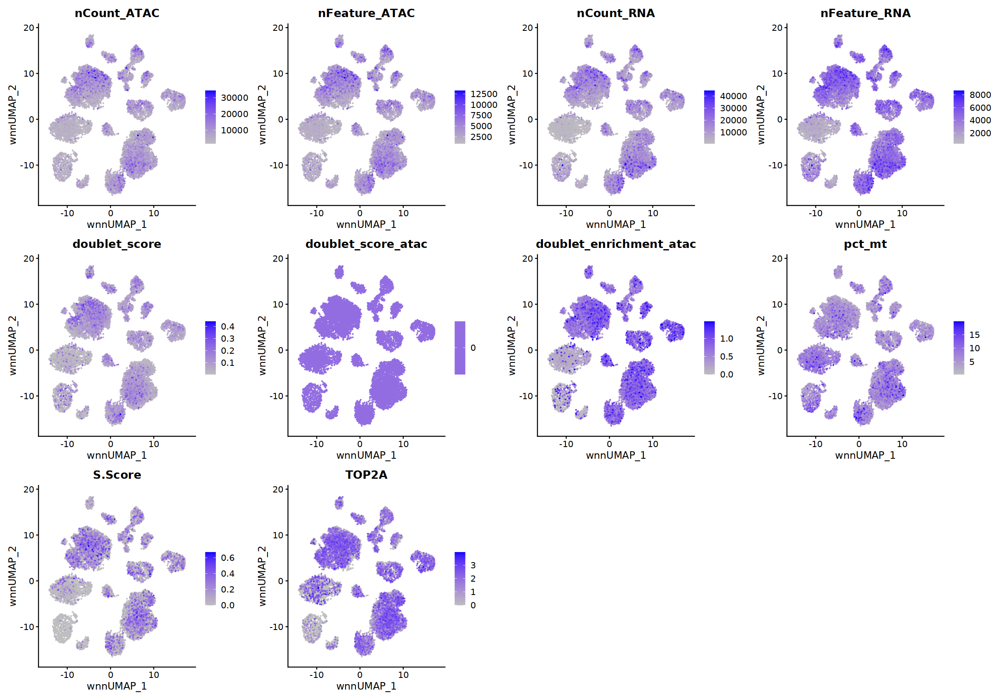

In [48]:
options(repr.plot.width = 20, repr.plot.height = 14)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt", "S.Score", "TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [49]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13

Calculating cluster 14



In [50]:
rna.markers %>% 
  dplyr::filter(cluster == "5") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=40)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
COL25A11,1.694809e-267,2.267081,0.780,0.194,5.443048e-263,5,COL25A1
XYLT1,0.000000e+00,2.031090,0.444,0.027,0.000000e+00,5,XYLT1
EFNA51,2.484688e-236,2.024034,0.762,0.206,7.979826e-232,5,EFNA5
NLGN11,2.375572e-138,1.921368,0.641,0.219,7.629387e-134,5,NLGN1
NTNG13,4.071839e-260,1.819113,0.723,0.164,1.307712e-255,5,NTNG1
CDH21,4.253619e-134,1.779319,0.389,0.086,1.366092e-129,5,CDH2
CSMD11,4.595609e-19,1.737101,0.211,0.103,1.475926e-14,5,CSMD1
HPSE22,4.229140e-234,1.646846,0.815,0.225,1.358230e-229,5,HPSE2
SULF11,2.335929e-184,1.614891,0.385,0.062,7.502070e-180,5,SULF1


### Rename

In [51]:
rename_clusters <- c("0"="Tumor GPC5",
                     "1"="Tumor CDH18",
                     "2"="T-cells",
                     "3"="Tumor TAFA2",
                     "4"="Tumor ROBO2",
                     "5"="Tumor COL25A1",
                     "6"="Monocytes-Macrophages", 
                     "7"="Tumor ANK2",
                     "8"="Tumor SEMA5A",
                     "9"="Tumor NRG1", 
                     "10"="Tumor GABRG3",
                     "11"="Tumor FN1",
                     "12"="Tumor EYA4",
                     "13"="Plasma B-cell",
                     "14"="Tumor PTPRD")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [52]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [53]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [54]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [55]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [56]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune



In [57]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

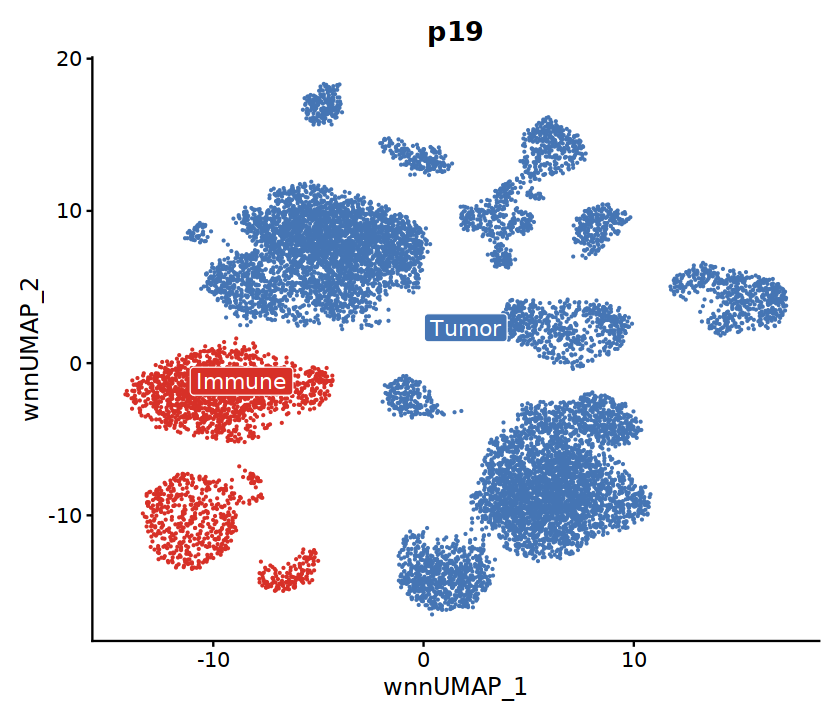

In [58]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [59]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [60]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [61]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

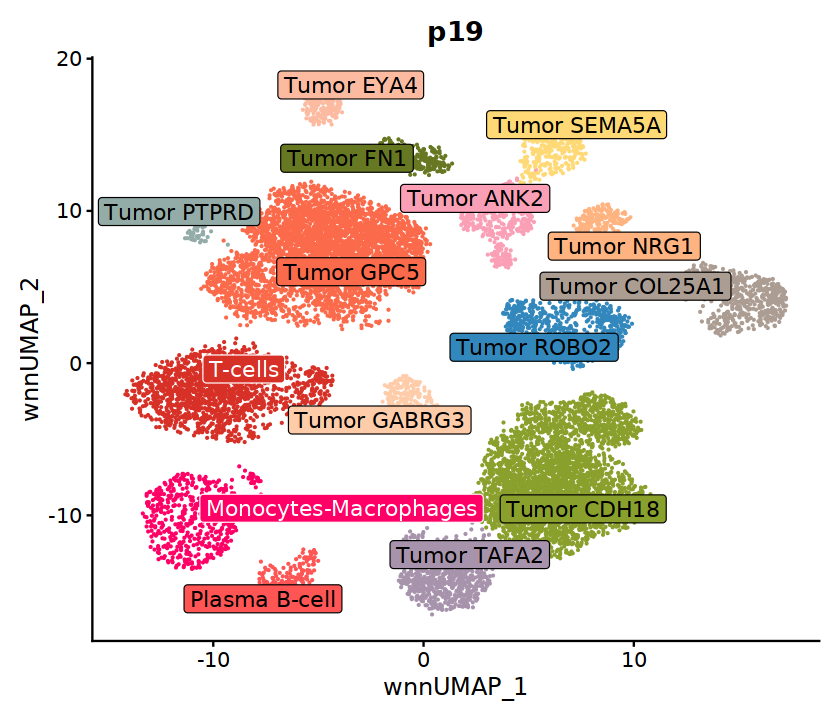

In [62]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [63]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

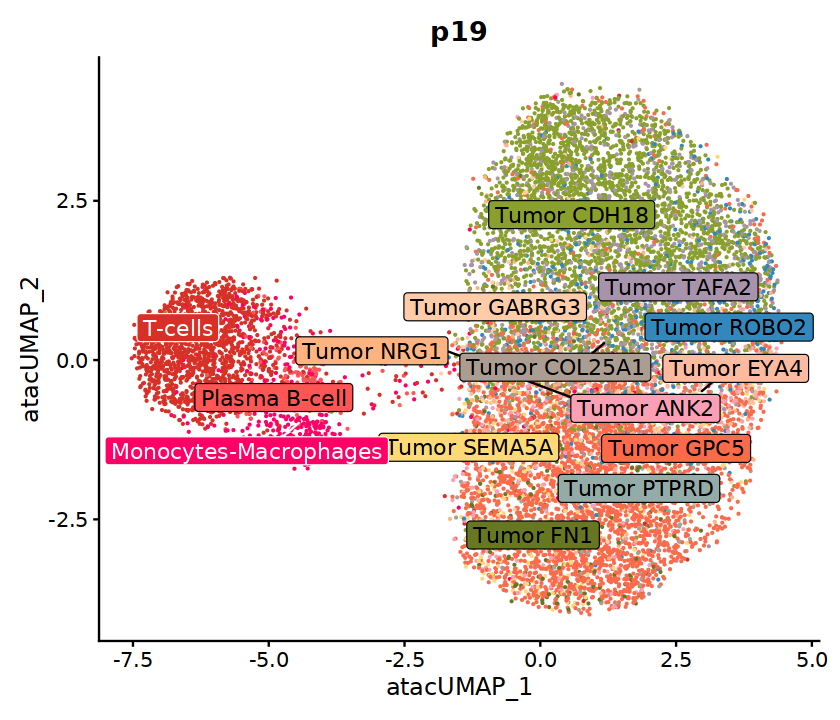

In [64]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [65]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

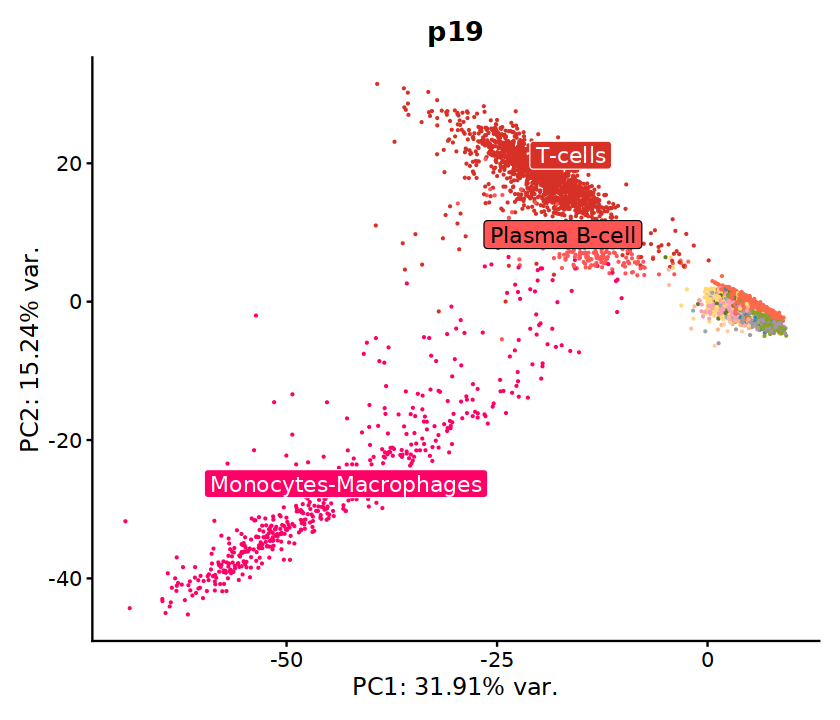

In [66]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

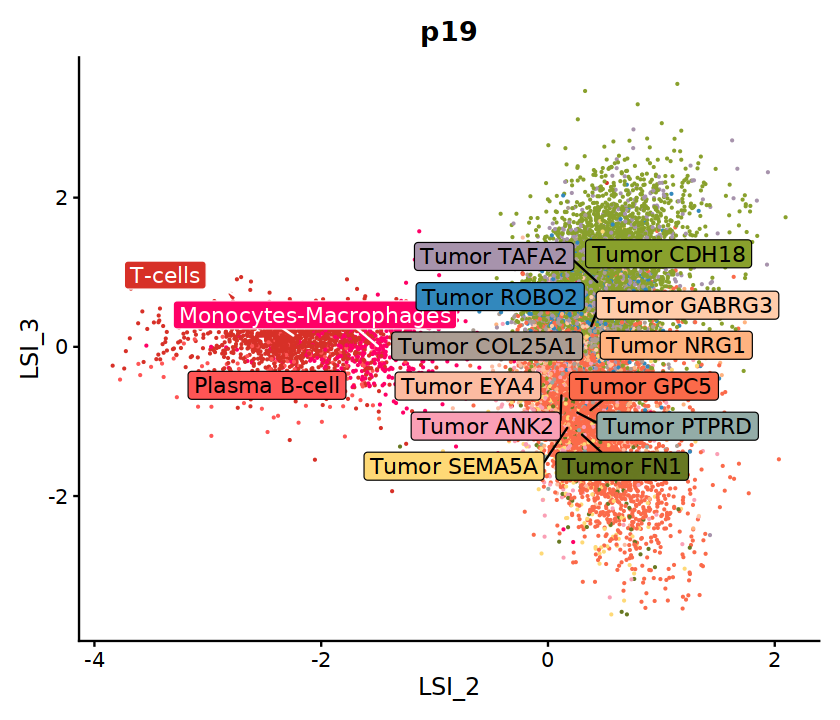

In [67]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

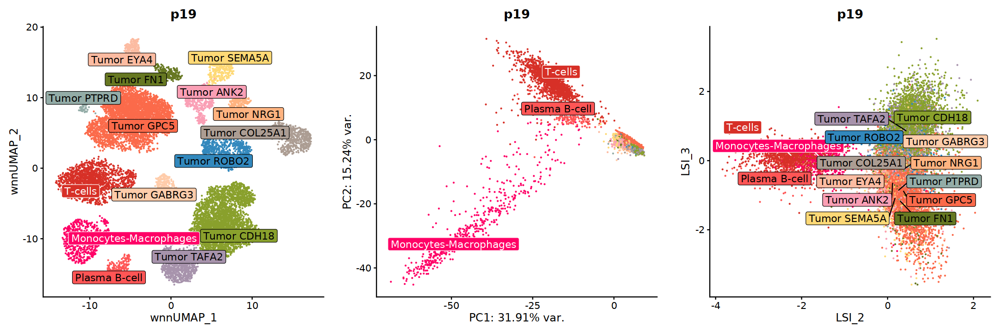

In [68]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [69]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [70]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("SOX4","GPC6", "SGCZ"), markers) ## common markers to all clusters

In [71]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

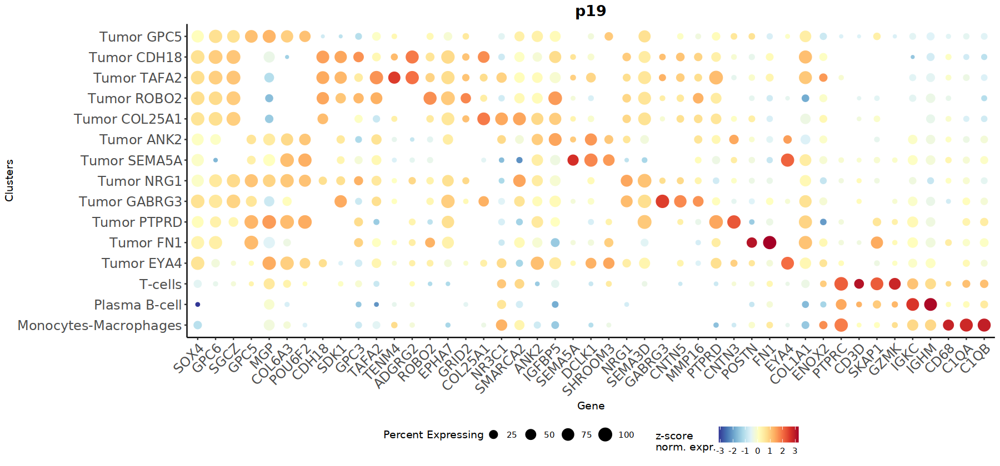

In [72]:
options(repr.plot.width = 15, repr.plot.height = 7, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

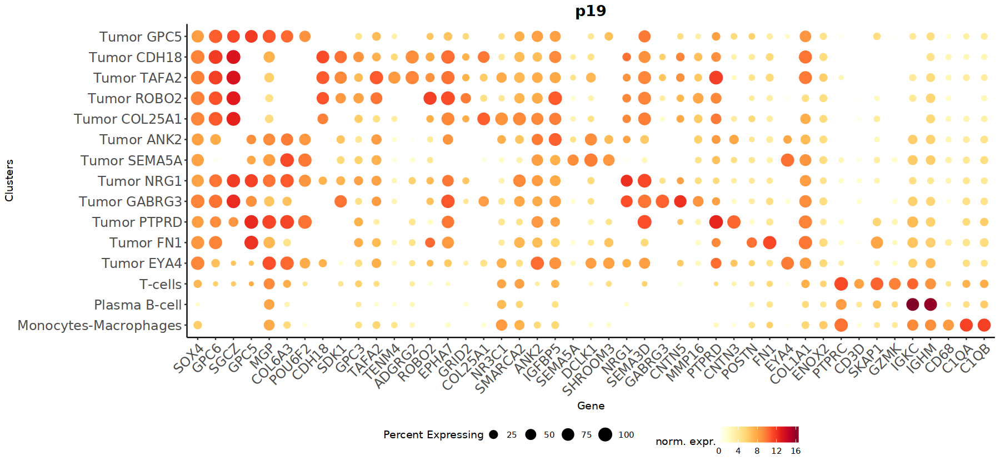

In [73]:
options(repr.plot.width = 15, repr.plot.height = 7, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [74]:
ggsave(plot = dp1, width = 15, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [75]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [76]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [77]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [78]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    